<a href="https://colab.research.google.com/github/Anirbit-AI/Expositions-With-PyTorch/blob/main/FourCastnet_Blowup_Under_Rollout.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reproducing the simplest experiment from *``Can AI Weather Models Predict Beyond Two Weeks?''*

This notebook reproduces the **FourCastNet** row of the paper's blow-up benchmark (Table 1) and the matching Arctic 2-metre temperature panel of Figure 1.

**What it does**

1. Loads FourCastNet (AFNO, 75M parameters, 0.25°, 6-hour step) through NVIDIA Earth2Studio, the platform the paper used.
2. Initialises it from ERA5 on **1 January 2021, 00 UTC** and rolls it out autoregressively.
3. Tracks the global minimum and maximum of T2m, U10m, MSLP and Z500 at every step.
4. Applies the paper's own blow-up detector (cloned from the authors' repository) with the FourCastNet-specific 10-day window from Appendix B.1.
5. Plots the Arctic T2m mean and min–max range against ERA5.

**Paper's result to compare against (Table 1, FourCastNet):** blow-up after **8, 8, 8 and 9 days** for T2m, U10m, MSLP and Z500.

**Requirements:** a Colab GPU runtime (*Runtime → Change runtime type → T4 GPU*). The default 60-day rollout takes a few minutes of GPU time plus a few minutes to download ERA5 reference fields.

## 1. Install

In [2]:
!pip install -q "earth2studio[fcn]"
!git clone -q --depth 1 https://github.com/lehmannfa/ai-weather-stability.git /content/ai-weather-stability || true
# If Colab asks you to restart the session after this cell, restart and continue from the next cell.

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.


## 2. Configuration

In [3]:
import numpy as np
import pandas as pd
import torch

INIT_TIME = "2021-01-01T00:00"        # initial condition used in the paper
N_DAYS = 60                           # rollout length in days (paper: 730; FourCastNet blows up long before 60)
STEPS_PER_DAY = 4                     # 6-hour model step
VARS = {"t2m": "T2m", "u10m": "U10m", "msl": "MSLP", "z500": "Z500"}  # FourCastNet variables in Table 1
ARCTIC_LAT = 66.5                     # Arctic = north of the Arctic Circle (our choice; the paper does not state its mask)
BLOWUP_WINDOW_DAYS = 10               # paper uses 30 days, reduced to 10 for FourCastNet (Appendix B.1)
SNAPSHOT_DAYS = [0, 4, 8, 12]         # days at which to save T2m maps

assert torch.cuda.is_available(), "Switch to a GPU runtime: Runtime -> Change runtime type -> T4 GPU"
device = torch.device("cuda")
print(torch.cuda.get_device_name(0))

Tesla T4


## 3. Load FourCastNet and the ERA5 initial condition

In [4]:
# Install earth2studio in case the environment was reset
!pip install -q "earth2studio[fcn]"

import torch
import numpy as np
from earth2studio.models.px import FCN
from earth2studio.data import ARCO, fetch_data
from earth2studio.utils.coords import map_coords
from earth2studio.utils.time import to_time_array
from earth2studio.lexicon import ARCO_ERA5Lexicon

# Safely verify and define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Instantiate model to get required input variables
model = FCN.load_model(FCN.load_default_package()).to(device)
ic = model.input_coords()

# Configure Lexicon to safely map ARCO variables
ARCO_ERA5Lexicon.VOCAB.clear()
ARCO_ERA5Lexicon.VOCAB["t2m"] = "2m_temperature"
ARCO_ERA5Lexicon.VOCAB["u10m"] = "10m_u_component_of_wind"
ARCO_ERA5Lexicon.VOCAB["v10m"] = "10m_v_component_of_wind"
ARCO_ERA5Lexicon.VOCAB["u100m"] = "100m_u_component_of_wind"
ARCO_ERA5Lexicon.VOCAB["v100m"] = "100m_v_component_of_wind"
ARCO_ERA5Lexicon.VOCAB["msl"] = "mean_sea_level_pressure"
ARCO_ERA5Lexicon.VOCAB["tcwv"] = "total_column_water_vapour"
ARCO_ERA5Lexicon.VOCAB["sp"] = "surface_pressure"

# All other required variables
for level in [1000, 925, 850, 700, 500, 300, 250, 200, 100, 50]:
    ARCO_ERA5Lexicon.VOCAB[f"z{level}"] = f"geopotential::{level}"
    ARCO_ERA5Lexicon.VOCAB[f"t{level}"] = f"temperature::{level}"
    ARCO_ERA5Lexicon.VOCAB[f"u{level}"] = f"u_component_of_wind::{level}"
    ARCO_ERA5Lexicon.VOCAB[f"v{level}"] = f"v_component_of_wind::{level}"
    ARCO_ERA5Lexicon.VOCAB[f"q{level}"] = f"specific_humidity::{level}"

era5 = ARCO()

# We will fetch all 24 successfully available variables, plus the q500/q850 needed for relative humidity calculations
all_vars = list(ic["variable"].values if hasattr(ic["variable"], "values") else ic["variable"])
fetch_vars = [v for v in all_vars if v not in ["r500", "r850"]]
if "q500" not in fetch_vars:
    fetch_vars.append("q500")
if "q850" not in fetch_vars:
    fetch_vars.append("q850")

print("Fetching variables from ARCO...")
x_fetched, coords_fetched = fetch_data(
    source=era5,
    time=to_time_array([INIT_TIME]),
    variable=fetch_vars,
    lead_time=ic["lead_time"],
    device=device,
)

# Calculate relative humidity (r) from temperature (t) and specific humidity (q)
# Formula: RH = 0.263 * p * q * exp(-17.67 * (t - 273.15) / (t - 29.65))^-1
def compute_rh(t_kelvin, q_val, pressure_hpa):
    t_celsius = t_kelvin - 273.15
    # Saturation vapor pressure (hPa) using Tetens equation
    es = 6.112 * torch.exp((17.67 * t_celsius) / (t_celsius + 243.5))
    # Vapor pressure e from specific humidity q and surface/level pressure p
    e = q_val * pressure_hpa / (0.378 * q_val + 0.622)
    rh = (e / es) * 100.0
    return torch.clamp(rh, 0.0, 100.0)

# Extract fetched components to calculate r500 and r850
var_list = list(coords_fetched["variable"])
t500 = x_fetched[:, :, var_list.index("t500")]
q500 = x_fetched[:, :, var_list.index("q500")]
r500 = compute_rh(t500, q500, 500.0).unsqueeze(2)

t850 = x_fetched[:, :, var_list.index("t850")]
q850 = x_fetched[:, :, var_list.index("q850")]
r850 = compute_rh(t850, q850, 850.0).unsqueeze(2)

# Reassemble the complete 26-variable tensor in the exact order requested by the model
x_assembled = []
for var in all_vars:
    if var == "r500":
        x_assembled.append(r500)
    elif var == "r850":
        x_assembled.append(r850)
    else:
        idx = var_list.index(var)
        x_assembled.append(x_fetched[:, :, idx:idx+1])

x0 = torch.cat(x_assembled, dim=2)
coords0 = coords_fetched.copy()
coords0["variable"] = np.array(all_vars)

x0, coords0 = map_coords(x0, coords0, ic)
print("Initial state:", tuple(x0.shape))

Using device: cuda


Fetching variables from ARCO...


Fetching ARCO_ERA5 data: 100%|██████████| 13/13 [00:12<00:00,  1.04it/s]


Initial state: (1, 1, 26, 720, 1440)


In [5]:
print(f"tcwv mapping: {ARCO_ERA5Lexicon.VOCAB.get('tcwv')}")
print(f"sp mapping:   {ARCO_ERA5Lexicon.VOCAB.get('sp')}")

tcwv mapping: total_column_water_vapour
sp mapping:   surface_pressure


In [6]:
print("All keys in ARCO_ERA5Lexicon.VOCAB:")
print(list(ARCO_ERA5Lexicon.VOCAB.keys()))

All keys in ARCO_ERA5Lexicon.VOCAB:
['t2m', 'u10m', 'v10m', 'u100m', 'v100m', 'msl', 'tcwv', 'sp', 'z1000', 't1000', 'u1000', 'v1000', 'q1000', 'z925', 't925', 'u925', 'v925', 'q925', 'z850', 't850', 'u850', 'v850', 'q850', 'z700', 't700', 'u700', 'v700', 'q700', 'z500', 't500', 'u500', 'v500', 'q500', 'z300', 't300', 'u300', 'v300', 'q300', 'z250', 't250', 'u250', 'v250', 'q250', 'z200', 't200', 'u200', 'v200', 'q200', 'z100', 't100', 'u100', 'v100', 'q100', 'z50', 't50', 'u50', 'v50', 'q50']


In [7]:
import asyncio
from earth2studio.data import fetch_data
from earth2studio.utils.time import to_time_array

requested_vars = list(ic["variable"].values if hasattr(ic["variable"], "values") else ic["variable"])
print(f"Total variables requested by model: {len(requested_vars)}")

successes = []
failures = []

for var in requested_vars:
    try:
        x_var, coords_var = fetch_data(
            source=era5,
            time=to_time_array([INIT_TIME]),
            variable=[var],
            lead_time=ic["lead_time"],
            device=device,
        )
        successes.append(var)
    except Exception as e:
        failures.append((var, str(e)))

print(f"\n--- Verification Summary ---")
print(f"Successfully fetched {len(successes)} variables.")
if failures:
    print(f"Failed to fetch {len(failures)} variables:")
    for f_var, err in failures:
        print(f"❌ {f_var}: {err}")
else:
    print("🎉 All variables fetched successfully!")

Total variables requested by model: 26


Fetching ARCO_ERA5 data: 100%|██████████| 1/1 [00:00<00:00,  3.15it/s]


2026-11-12 14:51:13.696 +00:00 | ERROR    | earth2studio.data.arco:fetch:228 - variable id r500 not found in ARCO_ERA5Lexicon
2026-11-12 14:51:13.699 +00:00 | ERROR    | earth2studio.data.arco:fetch:228 - variable id r850 not found in ARCO_ERA5Lexicon


Fetching ARCO_ERA5 data: 100%|██████████| 1/1 [00:00<00:00,  2.92it/s]


--- Verification Summary ---
Successfully fetched 24 variables.
Failed to fetch 2 variables:
❌ r500: 'r500'
❌ r850: 'r850'


## 4. Autoregressive rollout

Only summary statistics are kept at each step, so memory use stays flat however long the rollout is.

In [8]:
from tqdm.auto import tqdm

n_steps = N_DAYS * STEPS_PER_DAY
var_names = list(coords0["variable"])
vidx = {v: var_names.index(v) for v in VARS}

lat = torch.as_tensor(coords0["lat"], dtype=torch.float32, device=device)
arctic = lat >= ARCTIC_LAT
w_arctic = torch.cos(torch.deg2rad(lat[arctic]))
w_arctic = w_arctic / w_arctic.sum()

gmin = {v: np.full(n_steps + 1, np.nan) for v in VARS}
gmax = {v: np.full(n_steps + 1, np.nan) for v in VARS}
arc = {k: np.full(n_steps + 1, np.nan) for k in ("mean", "min", "max")}
snapshots = {}
first_nonfinite = None
nonfinite_day = {v: None for v in VARS}      # first day each variable contains NaN/inf
nan_streak = 0

with torch.inference_mode():
    for step, (x, c) in enumerate(tqdm(model.create_iterator(x0, coords0), total=n_steps + 1)):
        f = x.reshape(-1, *x.shape[-3:])[0]                       # (variable, lat, lon)
        for v, i in vidx.items():
            fi = f[i]
            if torch.isfinite(fi).all():
                gmin[v][step] = fi.min().item()
                gmax[v][step] = fi.max().item()
            elif nonfinite_day[v] is None:
                nonfinite_day[v] = step / STEPS_PER_DAY
        t2m = f[vidx["t2m"]]
        if torch.isfinite(t2m).all():
            a = t2m[arctic]
            arc["mean"][step] = (a.mean(-1) * w_arctic).sum().item()
            arc["min"][step] = a.min().item()
            arc["max"][step] = a.max().item()
            nan_streak = 0
        else:
            first_nonfinite = step if first_nonfinite is None else first_nonfinite
            nan_streak += 1
        if step % STEPS_PER_DAY == 0 and step // STEPS_PER_DAY in SNAPSHOT_DAYS:
            snapshots[step // STEPS_PER_DAY] = t2m[::4, ::4].float().cpu().numpy()
        if step == 0:
            print(f"Peak GPU memory after first step: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
        if step == n_steps or nan_streak > 8 * STEPS_PER_DAY:
            break

if first_nonfinite is not None:
    print(f"Non-finite values first appeared at day {first_nonfinite / STEPS_PER_DAY:.2f}")
days = np.arange(n_steps + 1) / STEPS_PER_DAY

  0%|          | 0/241 [00:00<?, ?it/s]

Peak GPU memory after first step: 0.5 GB


## 5. Blow-up time with the paper's detector

`detect_exponential_onset` is imported unchanged from the authors' repository. As in their `compute_blowup_days`, the global min and max series are smoothed with a centred 4-day running mean (16 steps), a log-linear regression is fitted over sliding windows, and blow-up is the start of the first window with R² > 0.9. The reported time is the earlier of the min and max onsets.

In [9]:
import sys
sys.path.insert(0, "/content/ai-weather-stability")
from metrics.blowup_time import detect_exponential_onset

def blowup_days(series_min, series_max, window_days):
    onsets = []
    for s in (series_min, series_max):
        s = pd.Series(s).replace([np.inf, -np.inf], np.nan)
        smooth = s.rolling(16, center=True).mean().values         # 4-day running mean, as in the paper's code
        _, onset = detect_exponential_onset(smooth, window_size=window_days * STEPS_PER_DAY)
        if onset is not None:
            onsets.append(onset)
    return min(onsets) / STEPS_PER_DAY if onsets else None

paper = {"t2m": 8, "u10m": 8, "msl": 8, "z500": 9}
rows = []
for v, label in VARS.items():
    d = blowup_days(gmin[v], gmax[v], BLOWUP_WINDOW_DAYS)
    rows.append({"variable": label,
                 "blow-up (days), this run": f"{d:.1f}" if d is not None else f"> {N_DAYS}",
                 "blow-up (days), paper": paper[v],
                 "first NaN/inf (day)": nonfinite_day[v]})
results = pd.DataFrame(rows)
# If a field turns NaN/inf within a few days of the onset, the 10-day regression window may not fit and
# the detector can miss the blow-up; the last column then shows when the rollout became unphysical.
results

,variable,"blow-up (days), this run","blow-up (days), paper",first NaN/inf (day)
0,T2m,5.5,8,None
1,U10m,5.2,8,None
2,MSLP,6.8,8,None
3,Z500,6.2,9,None


## 6. ERA5 reference for the Arctic (daily, 00 UTC)

In [10]:
ref_times = pd.date_range(INIT_TIME, periods=N_DAYS + 1, freq="1D")
ref = {k: [] for k in ("mean", "min", "max")}
for chunk in tqdm(np.array_split(ref_times, int(np.ceil(len(ref_times) / 8)))):
    da = era5(list(chunk.to_pydatetime()), ["t2m"]).sel(variable="t2m")
    da = da.where(da.lat >= ARCTIC_LAT, drop=True)
    w = np.cos(np.deg2rad(da.lat))
    ref["mean"] += list(da.mean("lon").weighted(w).mean("lat").values)
    ref["min"] += list(da.min(["lat", "lon"]).values)
    ref["max"] += list(da.max(["lat", "lon"]).values)
ref = {k: np.array(v) for k, v in ref.items()}
ref_days = np.arange(len(ref_times))

  0%|          | 0/8 [00:00<?, ?it/s]


Fetching ARCO_ERA5 data: 100%|██████████| 8/8 [00:02<00:00,  2.73it/s]

Fetching ARCO_ERA5 data: 100%|██████████| 8/8 [00:02<00:00,  2.69it/s]

Fetching ARCO_ERA5 data: 100%|██████████| 8/8 [00:01<00:00,  4.09it/s]

Fetching ARCO_ERA5 data: 100%|██████████| 8/8 [00:01<00:00,  4.10it/s]

Fetching ARCO_ERA5 data: 100%|██████████| 8/8 [00:01<00:00,  4.22it/s]

Fetching ARCO_ERA5 data: 100%|██████████| 7/7 [00:01<00:00,  3.59it/s]

Fetching ARCO_ERA5 data: 100%|██████████| 7/7 [00:01<00:00,  3.65it/s]

Fetching ARCO_ERA5 data: 100%|██████████| 7/7 [00:01<00:00,  3.69it/s]


## 7. Figure 1 panel: Arctic 2-metre temperature

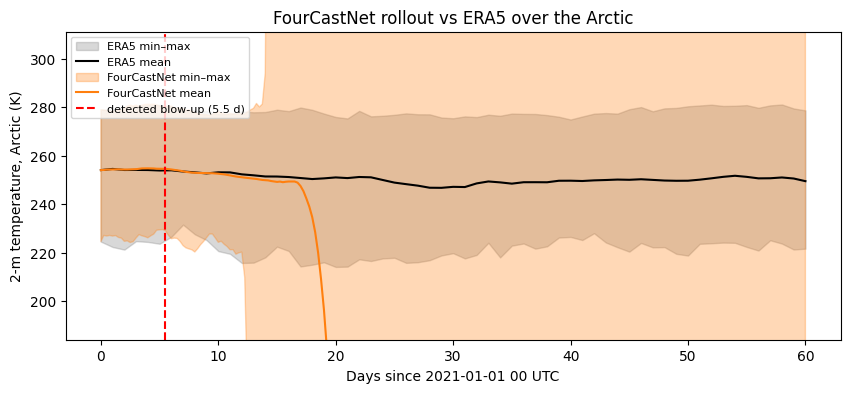

In [11]:
import matplotlib.pyplot as plt

t2m_blowup = blowup_days(gmin["t2m"], gmax["t2m"], BLOWUP_WINDOW_DAYS)
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(ref_days, ref["min"], ref["max"], color="grey", alpha=0.3, label="ERA5 min–max")
ax.plot(ref_days, ref["mean"], color="black", label="ERA5 mean")
ax.fill_between(days, arc["min"], arc["max"], color="tab:orange", alpha=0.3, label="FourCastNet min–max")
ax.plot(days, arc["mean"], color="tab:orange", label="FourCastNet mean")
if t2m_blowup is not None:
    ax.axvline(t2m_blowup, color="red", ls="--", label=f"detected blow-up ({t2m_blowup:.1f} d)")
lo, hi = np.nanmin(ref["min"]), np.nanmax(ref["max"])
ax.set_ylim(lo - 30, hi + 30)            # like the paper, do not follow the model into unphysical values
ax.set_xlabel("Days since 2021-01-01 00 UTC")
ax.set_ylabel("2-m temperature, Arctic (K)")
ax.set_title("FourCastNet rollout vs ERA5 over the Arctic")
ax.legend(loc="upper left", fontsize=8)
plt.show()

## 8. Global extremes behind the blow-up detection

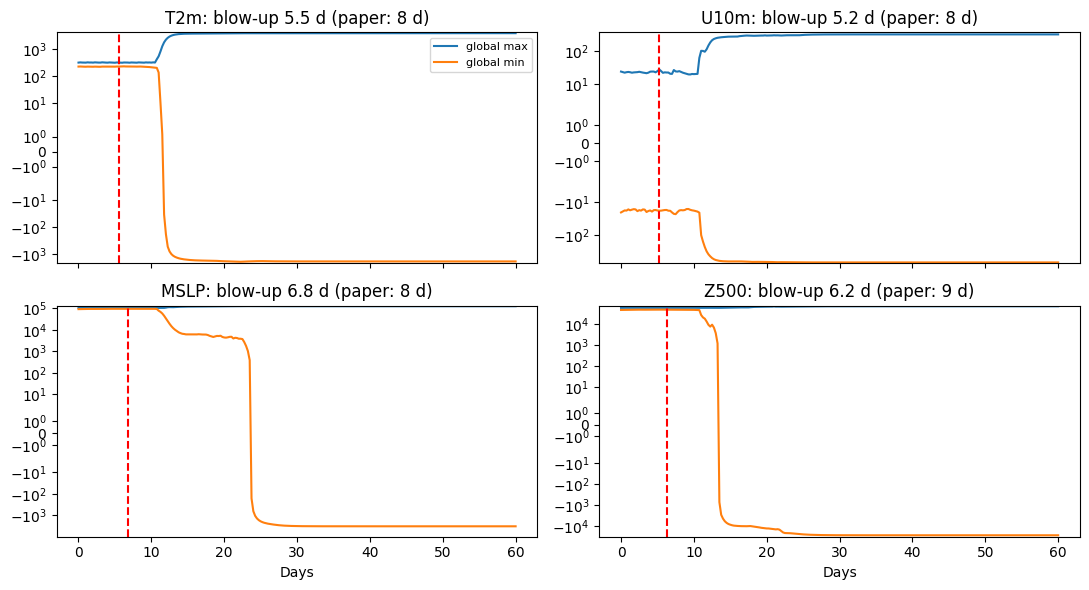

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, (v, label) in zip(axes.ravel(), VARS.items()):
    ax.plot(days, gmax[v], label="global max")
    ax.plot(days, gmin[v], label="global min")
    d = blowup_days(gmin[v], gmax[v], BLOWUP_WINDOW_DAYS)
    if d is not None:
        ax.axvline(d, color="red", ls="--")
    ax.set_title(f"{label}: blow-up {'%.1f d' % d if d is not None else 'not detected'} (paper: {paper[v]} d)")
    ax.set_yscale("symlog")
axes[0, 0].legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Days")
plt.tight_layout()
plt.show()

## 9. What the blow-up looks like

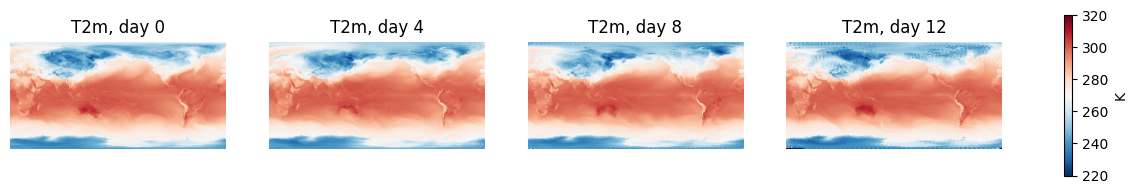

variable blow-up (days), this run  blow-up (days), paper first NaN/inf (day)
     T2m                      5.5                      8                None
    U10m                      5.2                      8                None
    MSLP                      6.8                      8                None
    Z500                      6.2                      9                None


In [13]:
fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 2.6))
axes = np.atleast_1d(axes)
for ax, (d, field) in zip(axes, sorted(snapshots.items())):
    im = ax.imshow(field, vmin=220, vmax=320, cmap="RdBu_r")
    ax.set_title(f"T2m, day {d}")
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8, label="K")
plt.show()

results.to_csv("fourcastnet_blowup.csv", index=False)
print(results.to_string(index=False))

## Notes

- **Expected agreement.** The weights are the same Earth2Studio FourCastNet checkpoint the paper used. The initial condition comes from Google's ARCO-ERA5 rather than WeatherBench2; both are ERA5 at 0.25°, so detected blow-up times should be close to the paper's but need not match to the day.
- **Arctic mask.** The paper does not specify its Arctic region; this notebook uses latitudes north of 66.5°N.
- **Longer rollouts.** Setting `N_DAYS = 730` reproduces the paper's 2-year horizon; it only adds GPU time, since memory use does not grow.
- **Other models.** The stable models (Aurora, SFNO, Pangu) need 2,920 steps to show their behaviour and, for Aurora and SFNO, more GPU memory or installation steps than the free tier comfortably provides.